> **Bản PyTorch** của `examples/5. Others/2_obj_detection.ipynb` (Keras). Người chuyển: TV3 – Võ Hoàng Bảo. Theo khuôn `1_MNIST_CNN` của BTL03.
> *(Gốc tham khảo từ https://github.com/HTuennermann/Vehicle-Detection-and-Tracking)*
>
> **Thay đổi so với bản Keras**
>
> - Ảnh đầu vào đổi từ `(N, 64, 64, 3)` (channels-last) sang `(N, 3, 64, 64)` (channels-first) bằng `np.transpose(..., (0, 3, 1, 2))`.
> - Lớp `Lambda(lambda x: x/127.5 - 1.)` → module `NormalizeInput(nn.Module)` đặt đầu `nn.Sequential(OrderedDict(...))`.
> - Giữ nguyên kiến trúc Fully Convolutional Network (FCN) với tổng **83,367 tham số**: `Conv2d` (`padding=1` cho `same`, `padding=0` cho `valid`), `MaxPool2d(8)`, `Dropout`, lớp cuối `Conv2d(128, 1, 1)` + `Tanh`.
> - Bài này dùng nhãn nhị phân `{-1, +1}` + đầu ra `tanh` + hàm mất mát **MSE** (`nn.MSELoss()`) giống bản gốc (không dùng `CrossEntropyLoss`); độ chính xác tính theo `torch.round(preds) == y` tương đương `metrics=['accuracy']` với MSE của Keras.
> - Lưu/nạp trọng số bằng `localize.pt` (`state_dict`) thay cho `localize.h5`. Khi suy luận trên ảnh `test.jpg` kích thước tùy ý (`heatmodel`), bỏ lớp `Flatten` ở cuối và lấy kênh heatmap theo trục PyTorch `heatmap[0, 0, :, :]` (thay cho `heatmap[0, :, :, 0]` của Keras).
> - Khởi tạo trọng số giống Keras (`xavier_uniform_`, bias `0`), cố định `SEED = 0` và `cudnn.deterministic = True`.

# Overview
- Simple object detector
- Input: RGB image
- Output: cars' locations

# Import libraries

In [1]:
import os
import glob
import time
from collections import OrderedDict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage.io import imread
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện (MSE + nhãn {-1, +1}); accuracy theo round giống Keras metrics=['accuracy']."""
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        preds = model(x)
        loss = loss_fn(preds, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (torch.round(preds) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (MSE loss, accuracy) trên cả tập."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x)
            total_loss += loss_fn(preds, y).item() * len(y)
            correct += (torch.round(preds) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in mỗi epoch giống Keras, trả về history."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về đầu ra tanh trực tiếp dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(model(xb).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader cho bài toán hồi quy / MSE nhãn float32."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32),
                       torch.tensor(np.asarray(y), dtype=torch.float32))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

# (1) Data
Giải nén `car_data.zip` cạnh notebook để có thư mục `./data/obj_detection/{vehicles,non-vehicles}/...` và đặt `test.jpg` cạnh notebook (xem `PHAN_CONG_NHIEM_VU.md` mục 3).

In [3]:
cars = sorted(glob.glob('./data/obj_detection/vehicles/*/*.png'))
non_cars = sorted(glob.glob('./data/obj_detection/non-vehicles/*/*.png'))
assert len(cars) > 0 and len(non_cars) > 0, 'Không tìm thấy dữ liệu trong ./data/obj_detection/'

Y = np.concatenate([np.ones(len(cars), dtype=np.float32), np.zeros(len(non_cars), dtype=np.float32) - 1.0])
def load_rgb(path):
    with Image.open(path) as img:
        return np.asarray(img.convert('RGB'))

X = np.array([load_rgb(name) for name in cars + non_cars], dtype=np.uint8)
print(f'cars: {len(cars)}, non-cars: {len(non_cars)}, X shape (NHWC): {X.shape}')

cars: 8792, non-cars: 8968, X shape (NHWC): (17760, 64, 64, 3)


In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.30, random_state=SEED)

# Keras: (N, 64, 64, 3)  ->  PyTorch: (N, 3, 64, 64)
X_train = np.transpose(X_train, (0, 3, 1, 2)).astype('float32')
X_test = np.transpose(X_test, (0, 3, 1, 2)).astype('float32')
Y_train = Y_train.reshape(-1, 1).astype('float32')
Y_test = Y_test.reshape(-1, 1).astype('float32')

print('X_train shape:', X_train.shape)
print(X_train.shape[0], 'train samples')
print(X_test.shape[0], 'test samples')

X_train shape: (12432, 3, 64, 64)
12432 train samples
5328 test samples


# (2) Declare model

In [5]:
class NormalizeInput(nn.Module):
    """Thay cho Keras Lambda(lambda x: x / 127.5 - 1.)."""
    def forward(self, x):
        return x / 127.5 - 1.0


def get_conv(filename=None):
    """Mạng Fully Convolutional nhận ảnh kích thước tùy ý (3, H, W) và xuất heatmap (1, H_out, W_out)."""
    net = nn.Sequential(OrderedDict([
        ('lambda_norm', NormalizeInput()),
        ('conv1', nn.Conv2d(3, 10, kernel_size=3, padding=1)),
        ('relu1', nn.ReLU()),
        ('conv2', nn.Conv2d(10, 10, kernel_size=3, padding=1)),
        ('relu2', nn.ReLU()),
        ('pool1', nn.MaxPool2d(kernel_size=8)),
        ('dropout1', nn.Dropout(0.25)),
        ('dense1', nn.Conv2d(10, 128, kernel_size=8, padding=0)),
        ('relu_dense1', nn.ReLU()),
        ('dropout2', nn.Dropout(0.5)),
        ('dense2', nn.Conv2d(128, 1, kernel_size=1)),
        ('tanh', nn.Tanh()),
    ])).to(device)
    if filename:
        net.load_state_dict(torch.load(filename, map_location=device, weights_only=True))
    else:
        init_like_keras(net)
    return net


backbone = get_conv()
model = nn.Sequential(OrderedDict([
    *backbone.named_children(),
    ('flatten', nn.Flatten()),
])).to(device)

summary(model, (3, 64, 64))   # Keras: 83,367 tham số

Layer (type)                        Output Shape               Param #
lambda_norm (NormalizeInput)        (None, 3, 64, 64)                0
conv1 (Conv2d)                      (None, 10, 64, 64)             280
relu1 (ReLU)                        (None, 10, 64, 64)               0
conv2 (Conv2d)                      (None, 10, 64, 64)             910
relu2 (ReLU)                        (None, 10, 64, 64)               0
pool1 (MaxPool2d)                   (None, 10, 8, 8)                 0
dropout1 (Dropout)                  (None, 10, 8, 8)                 0
dense1 (Conv2d)                     (None, 128, 1, 1)           82,048
relu_dense1 (ReLU)                  (None, 128, 1, 1)                0
dropout2 (Dropout)                  (None, 128, 1, 1)                0
dense2 (Conv2d)                     (None, 1, 1, 1)                129
tanh (Tanh)                         (None, 1, 1, 1)                  0
flatten (Flatten)                   (None, 1)                        0
Total 

# (3) Train defined model

In [6]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

batch_size = 128
epochs = 5
train_loader = make_loader(X_train, Y_train, batch_size, shuffle=True)
test_loader = make_loader(X_test, Y_test, batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs)
print('> training time is %.4f minutes (%.2f seconds)' % ((time.time() - starting_time) / 60, time.time() - starting_time))

score = evaluate(model, test_loader, loss_fn)
print('Test score:', score[0])
print('Test accuracy:', score[1])

# Lưu trọng số phần conv (tương đương model.save_weights('localize.h5'))
torch.save(backbone.state_dict(), 'localize.pt')
print('Saved weights to localize.pt')

Epoch 1/5 - 2.7s - loss: 0.3996 - accuracy: 0.5898 - val_loss: 0.1093 - val_accuracy: 0.9015


Epoch 2/5 - 1.4s - loss: 0.1143 - accuracy: 0.9106 - val_loss: 0.1102 - val_accuracy: 0.9292


Epoch 3/5 - 1.5s - loss: 0.0814 - accuracy: 0.9398 - val_loss: 0.0961 - val_accuracy: 0.9407


Epoch 4/5 - 1.4s - loss: 0.0694 - accuracy: 0.9516 - val_loss: 0.0452 - val_accuracy: 0.9681


Epoch 5/5 - 1.4s - loss: 0.0566 - accuracy: 0.9598 - val_loss: 0.0394 - val_accuracy: 0.9728
> training time is 0.1407 minutes (8.44 seconds)


Test score: 0.03938275418319815
Test accuracy: 0.9727852852852853
Saved weights to localize.pt


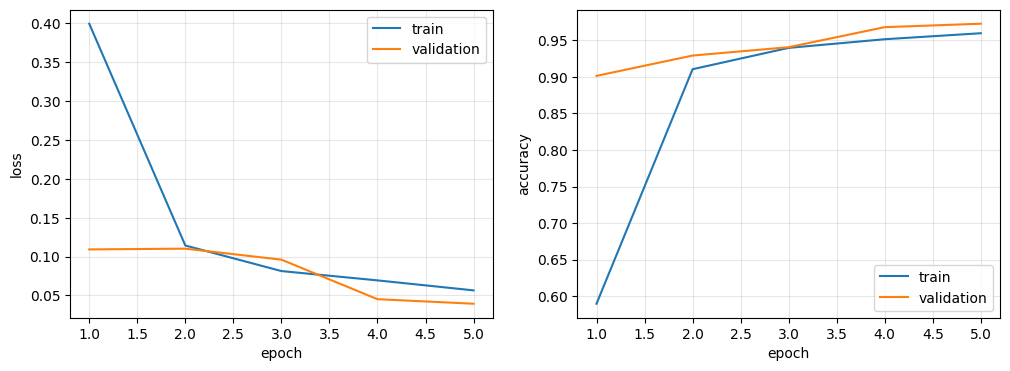

In [7]:
plot_history(history)

### Training time
- Bản Keras gốc: ~12 giây (0.20 phút) cho 5 epoch, Test score (MSE) 0.0642, Test accuracy 0.9523
- Bản PyTorch: xem kết quả ô trên (NVIDIA GeForce RTX 3050 Laptop GPU)

# (4) Evaluate trained model

In [8]:
# Nạp lại trọng số vào mô hình FCN (không có Flatten) để chạy trên ảnh kích thước bất kỳ
heatmodel = get_conv(filename='localize.pt')

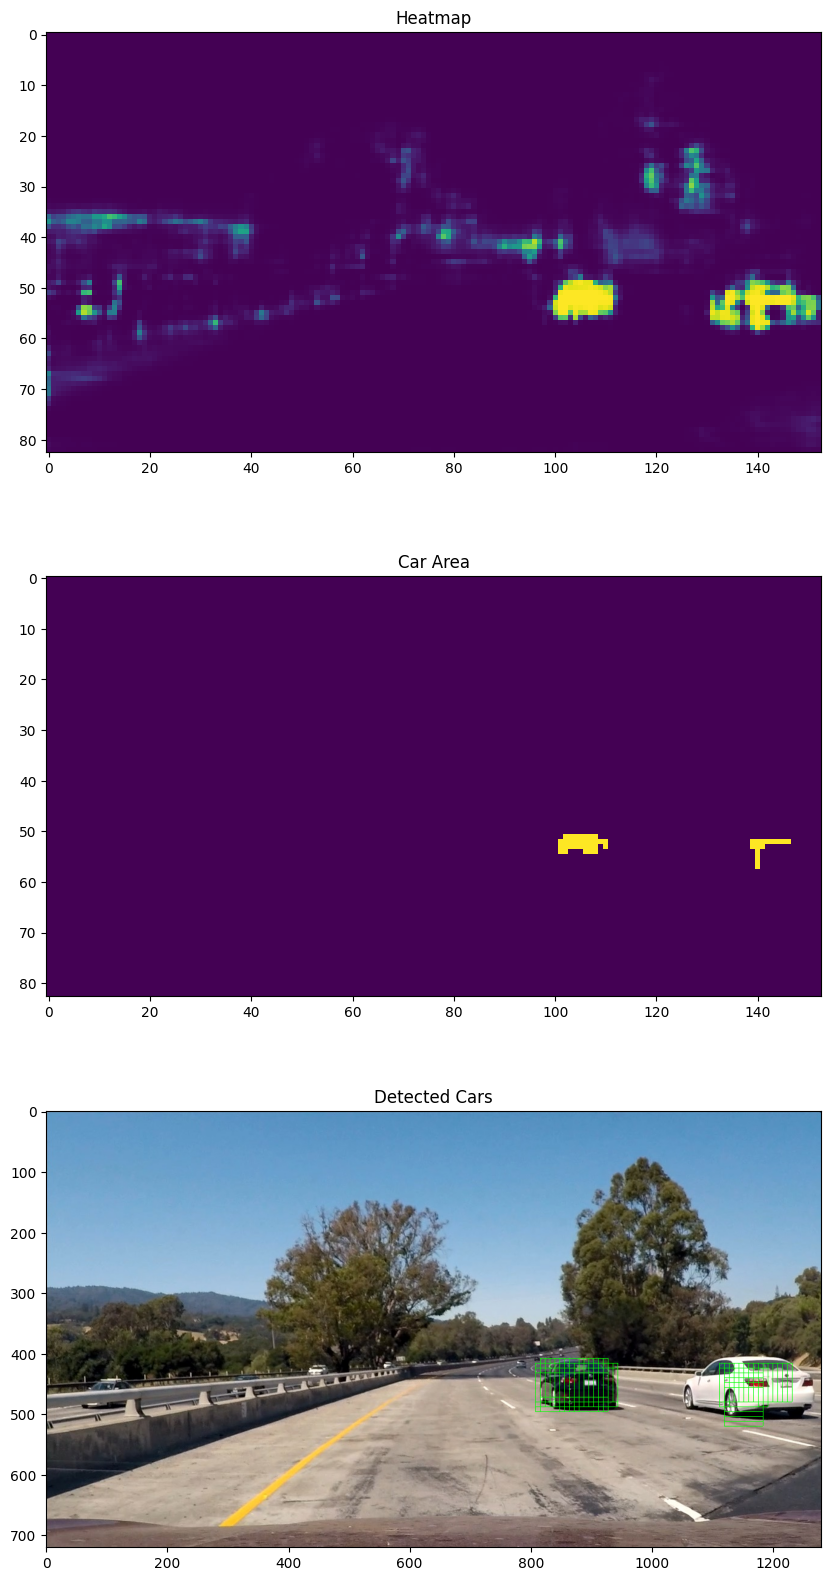

In [9]:
def locate(threshold=0.99):
    data = imread('test.jpg').copy()

    # Keras: (1, H, W, 3) -> PyTorch: (1, 3, H, W)
    inp = np.transpose(data, (2, 0, 1))[np.newaxis, ...].astype(np.float32)
    heatmap = predict(heatmodel, inp)       # (1, 1, H_out, W_out)
    hm = heatmap[0, 0, :, :]                # Keras: heatmap[0, :, :, 0]
    sel_heatmap = hm > threshold

    xx, yy = np.meshgrid(np.arange(hm.shape[1]), np.arange(hm.shape[0]))
    x = xx[sel_heatmap]
    y = yy[sel_heatmap]

    h_img, w_img = data.shape[:2]
    for i, j in zip(x, y):
        y0, y1 = j * 8, min(j * 8 + 64, h_img - 1)
        x0, x1 = i * 8, min(i * 8 + 64, w_img - 1)
        data[y0:y1, x0] = (0, 255, 0)
        data[y0:y1, x1] = (0, 255, 0)
        data[y0, x0:x1] = (0, 255, 0)
        data[y1, x0:x1] = (0, 255, 0)
    return hm, sel_heatmap, data

hm, sel_hm, annotated = locate()

plt.figure(figsize=(10, 20))

plt.subplot(3, 1, 1)
plt.title('Heatmap')
plt.imshow(hm)

plt.subplot(3, 1, 2)
plt.title('Car Area')
plt.imshow(sel_hm)

plt.subplot(3, 1, 3)
plt.title('Detected Cars')
plt.imshow(annotated)
plt.show()